# Assignment 2

In [1]:
# imports section

import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import nltk
import numpy as np
import requests
import seaborn as sns
from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from spellchecker import SpellChecker

for resource in ('wordnet', 'omw-1.4', 'stopwords', 'averaged_perceptron_tagger_eng'):
    nltk.download(resource, quiet=True)

FIGURES_DIR = Path('figures') / 'assignment-2'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

REQUEST_TIMEOUT = 15  # seconds
HEADERS = {'User-Agent': 'ida-labs/1.0 (educational project)'}

## Extract data from the json file

Write a script, that would extract all the the data from the json file and return it in a list of texts for further use in the next tasks

In [2]:
def collect_strings(node):
    """Recursively yield every string value from parsed JSON (dicts, lists, scalars)."""
    if isinstance(node, str):
        yield node
    elif isinstance(node, dict):
        for value in node.values():
            yield from collect_strings(value)
    elif isinstance(node, list):
        for value in node:
            yield from collect_strings(value)


def extract_texts_from_file(file_path):
    """
    Extract the text data from the json file

    Args:
        file_path (str): Relative location of the json file in the project.

    Returns:
        list: The list of texts as strings.
    """
    with open(file_path, encoding='utf-8') as f:
        data = json.load(f)
    return [text for text in collect_strings(data) if text.strip()]

texts = extract_texts_from_file('resources/data.json')
print(texts)

['Oppenheimer, directed by Christopher Nolan, delves into the life of J. Robert Oppenheimer, the theoretical physicist who led the development of the atomic bomb. The film explores his moral and emotional struggles.', "Oppenheimer captures the life of the 'father of the atomic bomb' and his internal conflict after the success of the Manhattan Project. The film's complex narrative reflects on the cost of scientific achievement.", 'In Oppenheimer, Cillian Murphy delivers a riveting performance as the conflicted physicist who grapples with the consequences of his groundbreaking work on the atomic bomb, under the weight of global politics and ethics.', 'Oppenheimer is a cinematic exploration of ambition, guilt, and responsibility. Through stunning visuals and a thought-provoking story, Nolan brings the life of the brilliant but haunted physicist to the big screen.', 'Ducks are versatile waterfowl, known for their adaptability in freshwater and coastal habitats. With webbed feet and waterpr

## Process the texts

Write a script, that would process these texts. Processing should include:

- Lowercasing
- Removing Punctuation
- Removing Special Characters and Numbers
- Stemming or Lemmatization
- Handling Abbreviations
- Spelling Correction

In [3]:
# Expanded before punctuation is removed, otherwise "e.g." or "don't" would be broken apart.
ABBREVIATIONS = {
    r"\be\.g\.": 'for example',
    r"\bi\.e\.": 'that is',
    r"\betc\.": 'et cetera',
    r"\bvs\.?": 'versus',
    r"\bdr\.": 'doctor',
    r"\bmr\.": 'mister',
    r"\bmrs\.": 'missus',
    r"\bu\.s\.a?\.?": 'united states',
    r"\bu\.k\.": 'united kingdom',
    r"\bai\b": 'artificial intelligence',
    r"\bml\b": 'machine learning',
    r"\bnlp\b": 'natural language processing',
    r"\bwon't\b": 'will not',
    r"\bcan't\b": 'can not',
    r"n't\b": ' not',
    r"\bit's\b": 'it is',
    r"\bthat's\b": 'that is',
    r"\bthere's\b": 'there is',
    r"'re\b": ' are',
    r"'ve\b": ' have',
    r"'ll\b": ' will',
    r"'d\b": ' would',
    r"\bi'm\b": 'i am',
    r"'s\b": '',  # possessive: "Nolan's film" -> "Nolan film"
}

STOP_WORDS = set(stopwords.words('english'))
LEMMATIZER = WordNetLemmatizer()
SPELL = SpellChecker()


def expand_abbreviations(text):
    text = text.replace('’', "'").replace('‘', "'")
    for pattern, replacement in ABBREVIATIONS.items():
        text = re.sub(pattern, replacement, text, flags=re.IGNORECASE)
    return text


def correct_spelling(token):
    """Fix lowercase unknown words; capitalized ones are likely proper names (Nolan, Dijkstra)."""
    if token[0].isupper() or len(token) < 4 or token.lower() in SPELL:
        return token
    return SPELL.correction(token) or token


def wordnet_pos(tag):
    """Map a Penn Treebank tag to the WordNet POS the lemmatizer expects."""
    return {'J': wordnet.ADJ, 'V': wordnet.VERB, 'R': wordnet.ADV}.get(tag[0], wordnet.NOUN)


def process_text(text):
    text = expand_abbreviations(text)
    # Keeping only letters removes punctuation, special characters and numbers in one step.
    tokens = re.findall(r'[A-Za-z]+', text)
    tokens = [correct_spelling(token).lower() for token in tokens]
    lemmas = [LEMMATIZER.lemmatize(token, wordnet_pos(tag)) for token, tag in nltk.pos_tag(tokens)]
    return ' '.join(lemma for lemma in lemmas if lemma not in STOP_WORDS and len(lemma) > 1)


def process_texts(texts):
    """
    Process the texts

    Args:
        texts (list): list of str texts to be processed.

    Returns:
        list: The list of texts as strings processed by script.
    """
    return [process_text(text) for text in texts]

texts_processed = process_texts(texts)
print(texts_processed)

['oppenheimer direct christopher nolan delve life robert oppenheimer theoretical physicist lead development atomic bomb film explore moral emotional struggle', 'oppenheimer capture life father atomic bomb internal conflict success manhattan project film complex narrative reflect cost scientific achievement', 'oppenheimer cillian murphy delivers riveting performance conflicted physicist grapple consequence groundbreaking work atomic bomb weight global politics ethic', 'oppenheimer cinematic exploration ambition guilt responsibility stunning visuals thought provoke story nolan bring life brilliant haunt physicist big screen', 'duck versatile waterfowl know adaptability freshwater coastal habitat webbed foot waterproof feather excellent swimmer migrate long distance find food warmer climate', 'lamp spider talk yesterday fly nobody notice except toaster watch blue smell well today door laugh understand whisper secret orange sock', 'duck communicate use range vocalization include quack whis

## Calculate cosine similarities using TFIDF

Calculate the TFIDF score and cosine similarity between the texts. You may use gensim, write your own script using numpy or use other module. Output the result as a matrix $n\times n$  of cosine similarity scores (where $n$ is the length of texts list).

Extra credit: use word2vec word embeddings in vector spaces to get better TFIDF scores by representing each word as a vector.

In [4]:
def calcuate_tfidf(texts_processed):
    """
    Calculate TFIDF score between the texts in the list.

    Args:
        texts_processed (list): list of texts, processed in previous task.

    Returns:
        cosine_matrix (np.ndarray): a n x n matrix of cosine similarity scores.
    """
    # sublinear_tf dampens repeated words; rows are L2-normalized, so cosine == dot product.
    tfidf = TfidfVectorizer(sublinear_tf=True).fit_transform(texts_processed)
    return cosine_similarity(tfidf)

cosine_matrix = calcuate_tfidf(texts_processed)
print(np.round(cosine_matrix, 2))

[[1.   0.2  0.15 0.16 0.   0.   0.   0.   0.   0.  ]
 [0.2  1.   0.1  0.06 0.   0.   0.   0.   0.   0.  ]
 [0.15 0.1  1.   0.06 0.   0.   0.   0.   0.   0.  ]
 [0.16 0.06 0.06 1.   0.   0.   0.   0.   0.   0.  ]
 [0.   0.   0.   0.   1.   0.   0.06 0.   0.03 0.  ]
 [0.   0.   0.   0.   0.   1.   0.   0.   0.   0.  ]
 [0.   0.   0.   0.   0.06 0.   1.   0.04 0.07 0.04]
 [0.   0.   0.   0.   0.   0.   0.04 1.   0.13 0.1 ]
 [0.   0.   0.   0.   0.03 0.   0.07 0.13 1.   0.18]
 [0.   0.   0.   0.   0.   0.   0.04 0.1  0.18 1.  ]]


## Visualize data

Visualize the cosine_matrix data using matplotlib. Choose your own method of plotting the scores in a way, that the similarity indeces between texts would be instantly visible. Plot data about texts as well (a couple of first words in the document).

*Hint: remember heat maps, aren't they nice for this task?*

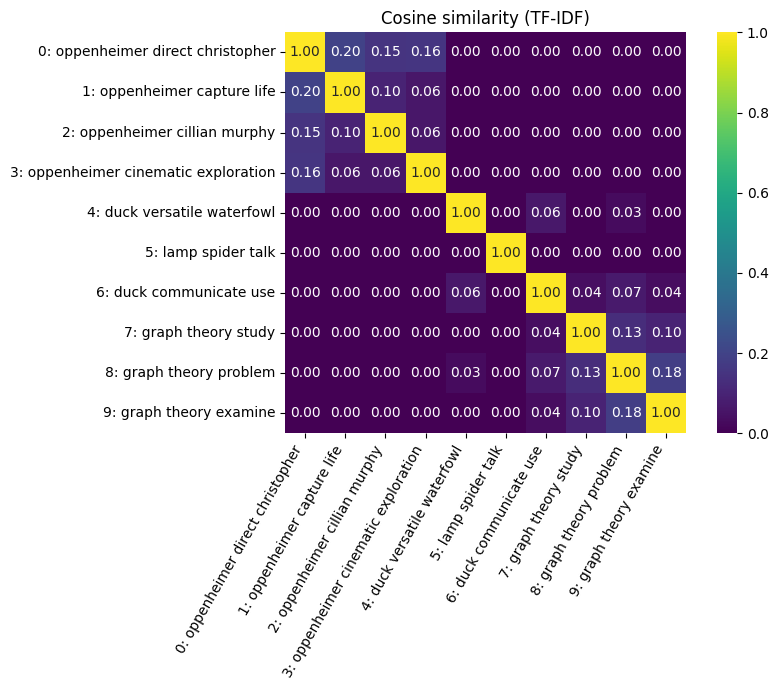

In [5]:
def visualize_data(cosine_matrix, texts_processed, title='Cosine similarity (TF-IDF)', file_name='cosine_similarity.png'):
    """
    Visualize the cosine similarity matrix from the previous task.

    Args:
        cosine_matrix (list): matrix of cosine similarity scores (values from 0.0 to 1.0 expected).
        texts_processed (list): list of texts, processed in previous task.
        title (str): Plot title.
        file_name (str): File name of the saved figure inside FIGURES_DIR.

    Returns:
        None: None.
    """
    labels = [f"{i}: {' '.join(text.split()[:3])}" for i, text in enumerate(texts_processed)]
    size = max(6, 0.7 * len(labels))

    fig, ax = plt.subplots(figsize=(size + 2, size))
    sns.heatmap(cosine_matrix, annot=True, fmt='.2f', cmap='viridis', vmin=0, vmax=1,
                xticklabels=labels, yticklabels=labels, square=True, ax=ax)
    ax.set_title(title)
    ax.tick_params(axis='x', rotation=60)
    plt.setp(ax.get_xticklabels(), ha='right')
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / file_name, dpi=120, bbox_inches='tight')
    plt.show()

visualize_data(cosine_matrix, texts_processed)

## Analyse your own text using TFIDF (or any other method)

Analyse your own text using previous methods. You may use API fetching to get text data, download texts from Kaggle or use any texts you want. Find cosine similarities and visualize them

Recommendation: use sentence_transform / openai embedding model

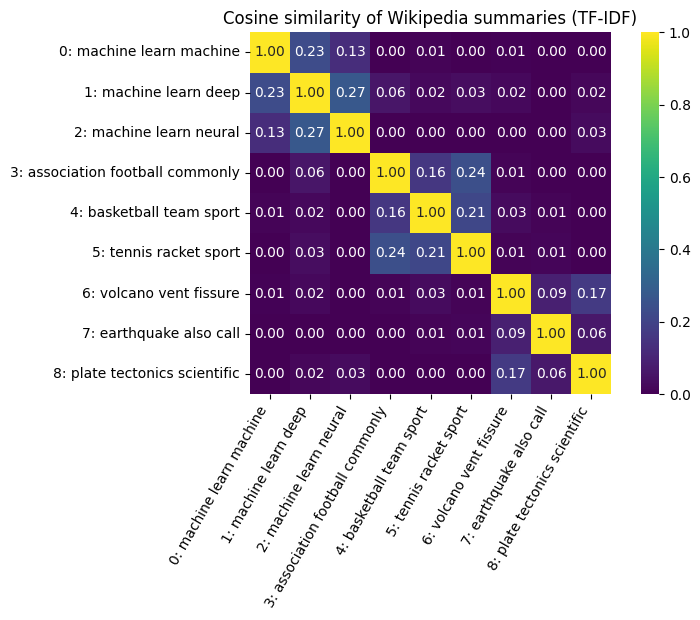

In [6]:
# Three topic groups, so a good similarity measure should show three bright blocks.
WIKIPEDIA_TOPICS = [
    'Machine_learning', 'Deep_learning', 'Artificial_neural_network',
    'Association_football', 'Basketball', 'Tennis',
    'Volcano', 'Earthquake', 'Plate_tectonics',
]


def get_texts(topics=WIKIPEDIA_TOPICS):
    """
    Get the texts you want to analyse. Either API fetching, Kaggle or any other source.

    Args:
        topics (list): Wikipedia article titles to fetch summaries for.

    Returns:
        list: list of texts.
    """
    texts = []
    for topic in topics:
        response = requests.get(f'https://en.wikipedia.org/api/rest_v1/page/summary/{topic}',
                                headers=HEADERS, timeout=REQUEST_TIMEOUT)
        response.raise_for_status()
        texts.append(response.json()['extract'])
    return texts

texts = get_texts()
texts_processed = process_texts(texts)
cosine_matrix = calcuate_tfidf(texts_processed)
visualize_data(cosine_matrix, texts_processed, title='Cosine similarity of Wikipedia summaries (TF-IDF)',
               file_name='wikipedia_cosine_similarity.png')